# 01 – Utforsking av løpedata

Første titt på løpeturene fra Garmin (mars 2025 → nå).

**Mål for denne notebooken:**
1. Laste inn og rydde dataene
2. Finne treningsperioder og pauser automatisk
3. Se på volum, tempo og form over tid
4. Skille mellom rolige, lange, tempo- og harde økter

## 1. Last inn data

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

DATA = Path("../data")

# thousands="," fordi Garmin skriver f.eks. "9,948" skritt
# na_values="--" fordi Garmin bruker "--" når en verdi mangler
raw = pd.read_csv(DATA / "Activities_løping.csv", thousands=",", na_values=["--"])
print(raw.shape)
raw.head(3)

(67, 37)


,Aktivitetstype,Dato,Favoritt,Tittel,Distanse,Totale kalorier,Tid,Gjennomsnittlig puls,Makspuls,Aerob treningseffekt,...,Dekompresjon,Beste rundetid,Antall runder,Gj. pust,Min. pust,Maks pust,Tid i bevegelse,Medgått tid,Minste høyde,Maksimal høyde
0,Løping,2026-11-17 18:55:30,False,Bergen - W10 Tue Easy Run - 7.5km Easy Ru,9.33,736,01:01:12,137,149,3.0,...,Nei,00:03:16.3,10,25.0,18.0,35.0,01:01:10,01:01:12,6,22.0
1,Løping,2026-11-15 14:02:49,False,Bergen - W9 Sun Long Run - 14km Block Lon,15.01,1215,01:24:27,158,171,4.6,...,Nei,00:00:02.0,16,36.0,13.0,47.0,01:24:20,01:25:13,3,37.0
2,Løping,2026-11-13 19:16:06,False,Bergen - W9 Thu Easy Run - 6.5km Easy Run,6.65,551,00:43:10,144,153,3.0,...,Nei,00:00:57.6,8,28.0,16.0,38.0,00:43:08,00:43:10,5,17.0


## 2. Rydd dataene

Garmin lagrer tid som tekst (`"01:01:12"`) og tempo som `"6:34"` (min/km).
Vi gjør dem om til sekunder så vi kan regne med dem.

In [ ]:
def tid_til_sek(s):
    """'01:01:12' eller '6:34' -> sekunder"""
    if pd.isna(s):
        return None
    sek = 0
    for d in str(s).split(":"):
        sek = sek * 60 + float(d)
    return sek


def sek_til_tempo(sek, _pos=None):
    """394 -> '6:34' (brukes også til akser i grafer)"""
    return f"{int(sek // 60)}:{int(sek % 60):02d}"


df = pd.DataFrame({
    "dato": pd.to_datetime(raw["Dato"]),
    "type": raw["Aktivitetstype"],
    "tittel": raw["Tittel"],
    "km": raw["Distanse"],
    "tid_s": raw["Tid"].map(tid_til_sek),
    "snittpuls": raw["Gjennomsnittlig puls"],
    "makspuls": raw["Makspuls"],
    "stigning_m": raw["Total stigning"],
    "kadens": raw["Gjennomsnittlig frekvens for løping"],
    "runder": raw["Antall runder"],
    # GAP = tempo justert for bakker
    "gap_s": raw["Gjennomsnittlig GAP"].map(tid_til_sek),
})

# Tempo regnet ut selv (sek per km) – mer presist enn Garmins avrundede tekst
df["tempo_s"] = df["tid_s"] / df["km"]
# GAP mangler på tredemølle – der er det jo flatt, så vanlig tempo duger
df["gap_s"] = df["gap_s"].fillna(df["tempo_s"])

# "Effektivitet": hvor mange meter du løper per hjerteslag. Høyere = bedre form.
df["meter_per_slag"] = (df["km"] * 1000) / (df["snittpuls"] * df["tid_s"] / 60)
# Samme mål, men med bakkejustert tempo: (meter per minutt) / (slag per minutt)
df["meter_per_slag_gap"] = (1000 / df["gap_s"] * 60) / df["snittpuls"]

df = df.sort_values("dato").reset_index(drop=True)
df.tail()

,dato,type,tittel,km,tid_s,snittpuls,makspuls,stigning_m,kadens,runder,gap_s,tempo_s,meter_per_slag,meter_per_slag_gap
62,2026-11-07 18:08:44,Løping,Bergen - 13km Hotspot Long Run,10.08,3613.0,150,173,58.0,159,11,363.0,358.432540,1.115970,1.101928
63,2026-11-10 19:24:38,Løping,Bergen - W8 Wed Time Trial - 5km Time Tri,6.19,1937.0,162,179,59.0,158,8,309.0,312.924071,1.183579,1.198610
64,2026-11-13 19:16:06,Løping,Bergen - W9 Thu Easy Run - 6.5km Easy Run,6.65,2590.0,144,153,29.0,161,8,389.0,389.473684,1.069820,1.071123
65,2026-11-15 14:02:49,Løping,Bergen - W9 Sun Long Run - 14km Block Lon,15.01,5067.0,158,171,81.0,164,16,339.0,337.574950,1.124926,1.120197
66,2026-11-17 18:55:30,Løping,Bergen - W10 Tue Easy Run - 7.5km Easy Ru,9.33,3672.0,137,149,33.0,163,10,395.0,393.569132,1.112781,1.108750


## 3. Finn treningsperioder automatisk

Hvis det går mer enn **4 uker** mellom to turer, regner vi det som en pause,
og neste tur starter en ny periode.

In [ ]:
PAUSE = pd.Timedelta(weeks=4)

df["dager_siden_forrige"] = df["dato"].diff().dt.days
df["periode"] = (df["dato"].diff() > PAUSE).cumsum()

perioder = df.groupby("periode").agg(
    start=("dato", "min"),
    slutt=("dato", "max"),
    turer=("km", "size"),
    km_totalt=("km", "sum"),
    snittempo_s=("tempo_s", "mean"),
    snittpuls=("snittpuls", "mean"),
    meter_per_slag=("meter_per_slag", "mean"),
)
perioder["varighet_uker"] = ((perioder["slutt"] - perioder["start"]).dt.days / 7).round(1)
perioder["snittempo"] = perioder["snittempo_s"].map(sek_til_tempo)
perioder.round({"km_totalt": 1, "snittempo_s": 0, "snittpuls": 0, "meter_per_slag": 2})

,start,slutt,turer,km_totalt,snittempo_s,snittpuls,meter_per_slag,varighet_uker,snittempo
periode,,,,,,,,,
0,2025-03-30 17:38:36,2025-05-06 19:04:08,9,59.2,331.0,150.0,1.22,5.3,5:30
1,2025-06-10 15:01:23,2025-08-24 14:06:29,8,46.0,350.0,159.0,1.09,10.6,5:50
2,2025-11-03 20:46:10,2025-11-03 20:46:10,1,3.4,369.0,144.0,1.13,0.0,6:09
3,2026-01-26 17:02:27,2026-01-26 17:02:27,1,1.9,609.0,137.0,0.72,0.0,10:08
4,2026-03-01 13:01:28,2026-07-06 15:10:41,23,136.8,391.0,157.0,1.01,18.1,6:30
5,2026-08-19 14:42:55,2026-11-17 18:55:30,25,209.8,372.0,151.0,1.08,12.9,6:11


In [ ]:
# De lengste pausene
df.nlargest(5, "dager_siden_forrige")[["dato", "dager_siden_forrige"]]

,dato,dager_siden_forrige
18,2026-01-26 17:02:27,83.0
17,2025-11-03 20:46:10,71.0
42,2026-08-19 14:42:55,43.0
9,2025-06-10 15:01:23,34.0
19,2026-03-01 13:01:28,33.0


## 4. Nøkkeltall

In [ ]:
print(f"Antall turer:      {len(df)}")
print(f"Total distanse:    {df['km'].sum():.0f} km")
print(f"Total tid:         {df['tid_s'].sum() / 3600:.1f} timer")
print(f"Lengste tur:       {df['km'].max():.1f} km ({df.loc[df['km'].idxmax(), 'dato']:%d.%m.%Y})")
raskest = df[df["km"] >= 5].nsmallest(1, "tempo_s").iloc[0]
print(f"Raskeste tur ≥5km: {sek_til_tempo(raskest['tempo_s'])} min/km "
      f"({raskest['km']:.1f} km, {raskest['dato']:%d.%m.%Y})")

Antall turer:      67
Total distanse:    457 km
Total tid:         46.4 timer
Lengste tur:       15.0 km (15.11.2026)
Raskeste tur ≥5km: 4:56 min/km (6.0 km, 07.04.2025)


## 5. Kilometer per uke

Ukene uten løping blir 0, så pausene syns som hull.

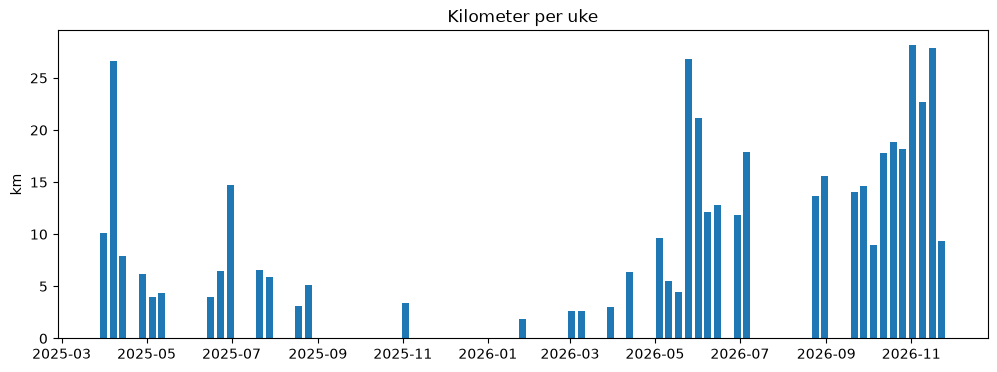

In [ ]:
uker = df.set_index("dato")["km"].resample("W-MON").sum()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(uker.index, uker.values, width=5)
ax.set_title("Kilometer per uke")
ax.set_ylabel("km")
plt.show()

## 6. Tempo over tid

Hver prikk er én tur, farget etter periode. Y-aksen er snudd så *raskere* er *høyere*.

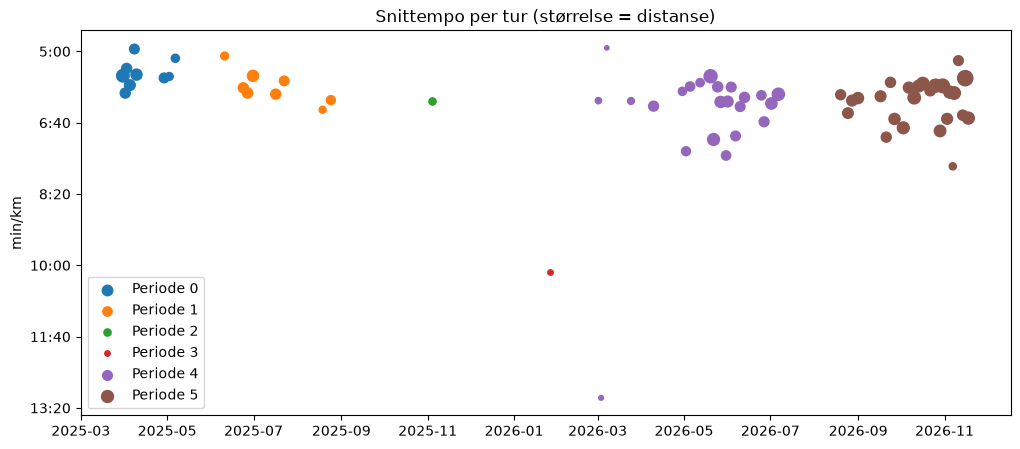

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
for p, gruppe in df.groupby("periode"):
    ax.scatter(gruppe["dato"], gruppe["tempo_s"], label=f"Periode {p}",
               s=gruppe["km"] * 8, color=f"C{p % 10}")

ax.invert_yaxis()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(sek_til_tempo))
ax.set_title("Snittempo per tur (størrelse = distanse)")
ax.set_ylabel("min/km")
ax.legend()
plt.show()

## 7. Form: meter per hjerteslag (alle turer)

Linjen er et glidende snitt over 5 turer, **innenfor hver periode** (ingen linje over pausene).
Se avsnitt 13 for en mer rettferdig versjon med bare rolige turer.

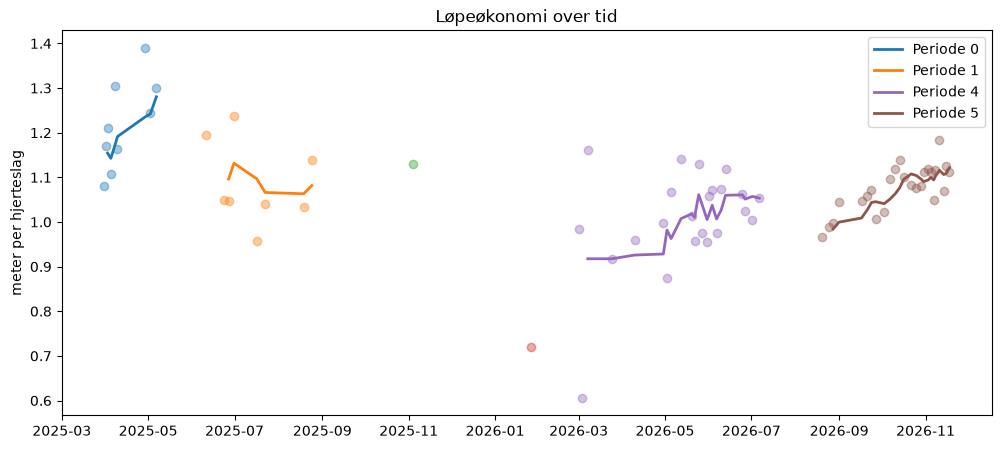

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
for p, gruppe in df.groupby("periode"):
    farge = f"C{p % 10}"  # samme farge på prikker og linje
    ax.scatter(gruppe["dato"], gruppe["meter_per_slag"], alpha=0.4, color=farge)
    if len(gruppe) >= 3:
        glatt = gruppe["meter_per_slag"].rolling(5, min_periods=3).mean()
        ax.plot(gruppe["dato"], glatt, linewidth=2, color=farge, label=f"Periode {p}")

ax.set_title("Løpeøkonomi over tid")
ax.set_ylabel("meter per hjerteslag")
ax.legend()
plt.show()

## 8. Puls mot tempo

Hvis formen blir bedre, skal prikkene flytte seg mot *raskere tempo ved samme puls*.
Fargen viser tid: mørk = gammel, lys = ny.

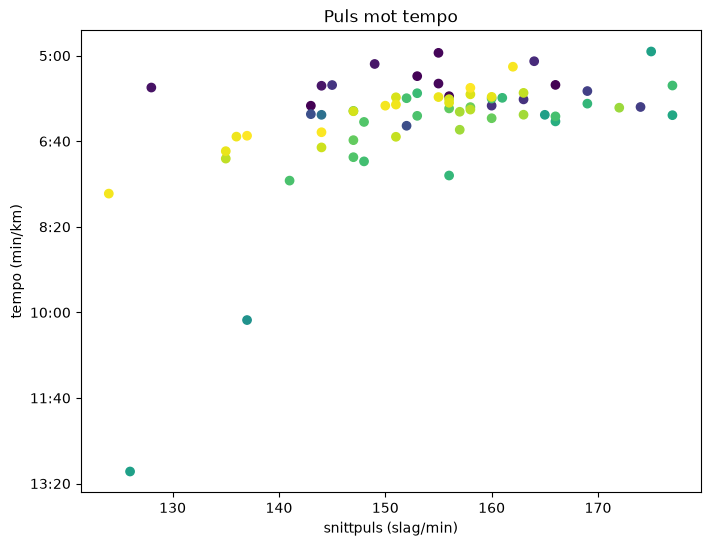

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["snittpuls"], df["tempo_s"], c=df["dato"].astype("int64"), cmap="viridis")
ax.invert_yaxis()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(sek_til_tempo))
ax.set_xlabel("snittpuls (slag/min)")
ax.set_ylabel("tempo (min/km)")
ax.set_title("Puls mot tempo")
plt.show()

## 9. Skill mellom rolige, lange, tempo- og harde økter

Runna-titlene sier hva slags økt det var (`Easy Run`, `Long Run`, `Tempo`, `Intervals` …).
Turer uten Runna-tittel (f.eks. «Oslo Løping») får en kvalifisert gjetning ut fra
distanse, antall runder og puls. Kolonnen `kilde` viser om typen kommer fra tittelen eller er gjettet.

In [ ]:
NØKKELORD = {
    # Rekkefølgen betyr noe: "hard" sjekkes først
    "hard": ["interval", "repeats", "pyramid", "time trial", "drop set", "broken miles", "hill", "fartlek"],
    "tempo": ["tempo", "threshold"],
    "lang": ["long"],
    "rolig": ["easy", "recovery"],
}


def okttype_fra_tittel(tittel):
    t = str(tittel).lower()
    for okttype, ord_ in NØKKELORD.items():
        if any(o in t for o in ord_):
            return okttype
    return None


def gjett_okttype(rad):
    """Enkle regler for turer uten Runna-tittel."""
    if rad["km"] >= 10:
        return "lang"
    if rad["runder"] / rad["km"] >= 1.8:  # intervaller gir mange korte runder
        return "hard"
    if rad["snittpuls"] <= 150:
        return "rolig"
    return "tempo"


df["okttype"] = df["tittel"].map(okttype_fra_tittel)
df["kilde"] = df["okttype"].notna().map({True: "tittel", False: "gjettet"})
df["okttype"] = df["okttype"].fillna(df.apply(gjett_okttype, axis=1))

# Fjern småturer og gåturer: under 2 km eller tregere enn 9:00 min/km
df["gyldig"] = (df["km"] >= 2) & (df["tempo_s"] <= 9 * 60)
g = df[df["gyldig"]]

print(g.groupby(["okttype", "kilde"]).size().unstack(fill_value=0))
print(f"\nFjernet som småturer/gåturer: {(~df['gyldig']).sum()}")

kilde    gjettet  tittel
okttype                 
hard           0      12
lang           2      12
rolig          8      12
tempo         11       7

Fjernet som småturer/gåturer: 3


In [ ]:
# Sjekk gjetningene – stemmer de med det du husker? Juster reglene over hvis ikke.
df[df["kilde"] == "gjettet"][["dato", "tittel", "km", "snittpuls", "runder", "okttype", "gyldig"]]

,dato,tittel,km,snittpuls,runder,okttype,gyldig
0,2025-03-30 17:38:36,Oslo Løping,10.13,166,7,lang,True
4,2025-04-07 20:00:09,Oslo Løping,6.05,155,4,tempo,True
6,2025-04-28 20:41:37,Bærum Løping,6.15,128,4,rolig,True
7,2025-05-02 12:00:53,Oslo Løping,4.01,144,3,rolig,True
8,2025-05-06 19:04:08,Oslo Løping,4.33,149,3,rolig,True
9,2025-06-10 15:01:23,Lombok Tengah Løping,4.01,164,3,tempo,True
10,2025-06-23 18:09:04,Oslo Løping,6.50,163,5,tempo,True
12,2025-06-30 14:44:56,Oslo Løping,8.01,145,5,rolig,True
17,2025-11-03 20:46:10,Løping på tredemølle,3.40,144,2,rolig,True
18,2026-01-26 17:02:27,Bergen Løping,1.90,137,2,rolig,False


## 10. Hvordan fordeler treningen seg?

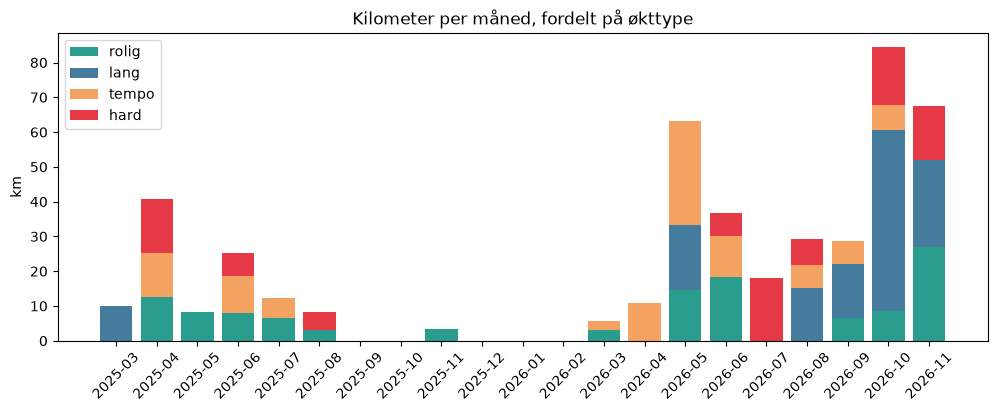

Andel av kilometerne:
  rolig    27 %
  lang     30 %
  tempo    23 %
  hard     20 %


In [ ]:
FARGER = {"rolig": "#2a9d8f", "lang": "#457b9d", "tempo": "#f4a261", "hard": "#e63946"}
TYPER = ["rolig", "lang", "tempo", "hard"]

mnd = (g.groupby([g["dato"].dt.to_period("M"), "okttype"])["km"].sum()
         .unstack(fill_value=0)
         .reindex(columns=TYPER, fill_value=0))
# Ta med måneder uten løping også, så pausene syns
mnd = mnd.reindex(pd.period_range(mnd.index.min(), mnd.index.max(), freq="M"), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4))
bunn = 0
for t in TYPER:
    ax.bar(mnd.index.astype(str), mnd[t], bottom=bunn, color=FARGER[t], label=t)
    bunn = bunn + mnd[t]
ax.set_title("Kilometer per måned, fordelt på økttype")
ax.set_ylabel("km")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.show()

andel = g.groupby("okttype")["km"].sum().reindex(TYPER) / g["km"].sum() * 100
print("Andel av kilometerne:")
for t, a in andel.items():
    print(f"  {t:6s} {a:4.0f} %")

## 11. Tempo og puls per økttype

Snitt per økttype i hver treningsperiode (bakkejustert tempo). Her ser du om de
rolige turene faktisk er rolige (lav puls), og om tempoet på samme type økt blir raskere.

In [ ]:
tabell = (g.groupby(["periode", "okttype"])
           .agg(turer=("km", "size"), snitt_km=("km", "mean"),
                tempo_s=("gap_s", "mean"), snittpuls=("snittpuls", "mean"))
           .reset_index())
tabell["tempo"] = tabell["tempo_s"].map(sek_til_tempo)
tabell.drop(columns="tempo_s").round(1)

,periode,okttype,turer,snitt_km,snittpuls,tempo
0,0,hard,2,7.7,155.5,5:41
1,0,lang,1,10.1,166.0,5:36
2,0,rolig,4,5.3,141.0,5:33
3,0,tempo,2,6.3,154.0,5:14
4,1,hard,2,5.9,151.5,6:05
5,1,rolig,3,5.9,157.0,5:58
6,1,tempo,3,5.5,165.3,5:30
7,2,rolig,1,3.4,144.0,6:09
8,4,hard,3,8.2,155.0,6:05
9,4,lang,2,9.3,165.0,5:52


## 12. Puls mot tempo, farget etter økttype

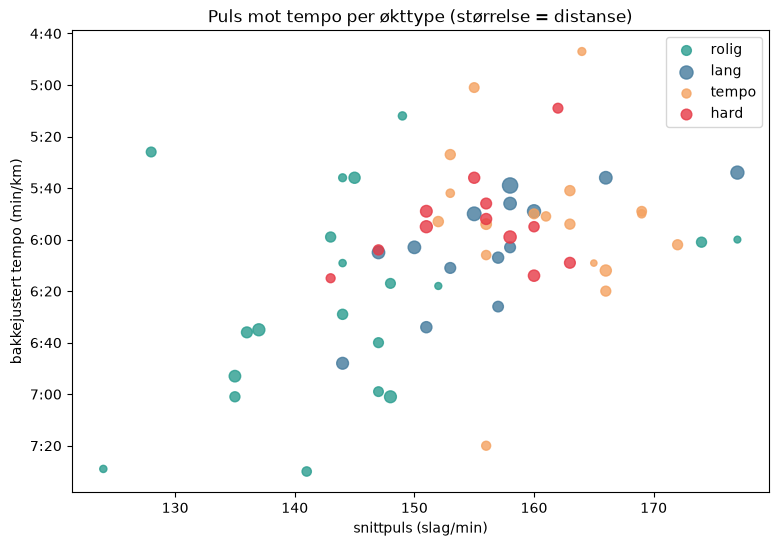

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
for t in TYPER:
    d = g[g["okttype"] == t]
    ax.scatter(d["snittpuls"], d["gap_s"], color=FARGER[t], label=t, s=d["km"] * 8, alpha=0.8)
ax.invert_yaxis()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(sek_til_tempo))
ax.set_xlabel("snittpuls (slag/min)")
ax.set_ylabel("bakkejustert tempo (min/km)")
ax.set_title("Puls mot tempo per økttype (størrelse = distanse)")
ax.legend()
plt.show()

## 13. Formen – bare rolige og lange turer

Det mest rettferdige formmålet: **meter per hjerteslag med bakkejustert tempo**,
bare for rolige og lange turer, der innsatsen er omtrent lik fra gang til gang.
Harde økter og intervaller er utelatt fordi pulsen der oppfører seg annerledes.

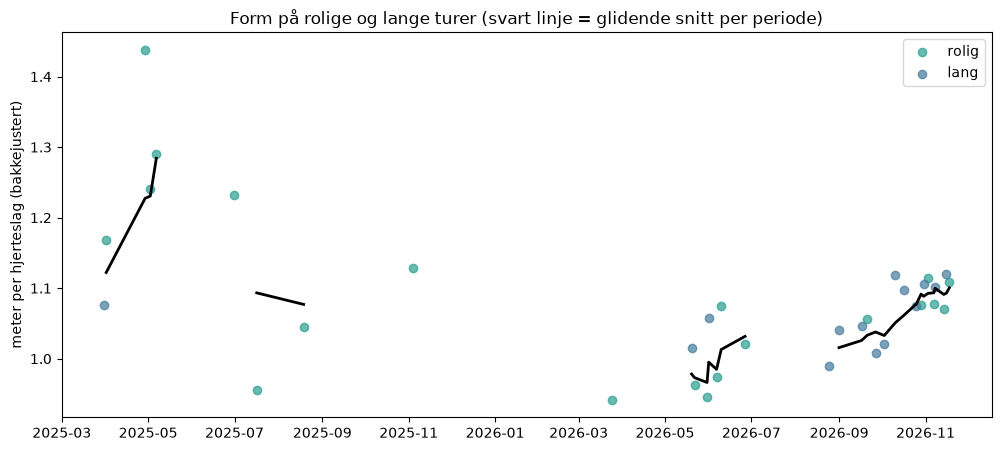

In [ ]:
rolige = g[g["okttype"].isin(["rolig", "lang"])]

fig, ax = plt.subplots(figsize=(12, 5))
for t in ["rolig", "lang"]:
    d = rolige[rolige["okttype"] == t]
    ax.scatter(d["dato"], d["meter_per_slag_gap"], color=FARGER[t], label=t, alpha=0.7)

for p, d in rolige.groupby("periode"):
    if len(d) >= 3:
        glatt = d["meter_per_slag_gap"].rolling(4, min_periods=2).mean()
        ax.plot(d["dato"], glatt, color="black", linewidth=2)

ax.set_title("Form på rolige og lange turer (svart linje = glidende snitt per periode)")
ax.set_ylabel("meter per hjerteslag (bakkejustert)")
ax.legend()
plt.show()

## Neste steg / ideer

- [x] Skille rolige, lange, tempo- og harde økter
- [ ] Sjekke gjetningene for turer uten Runna-tittel og justere reglene
- [ ] Ta med styrketrening fra `Activities_all.csv`
- [ ] Når Strava-arkivet kommer: legge til turene fra før mars 2025
- [ ] Flytte logikken til et skript som lager `stats.json` til nettsiden